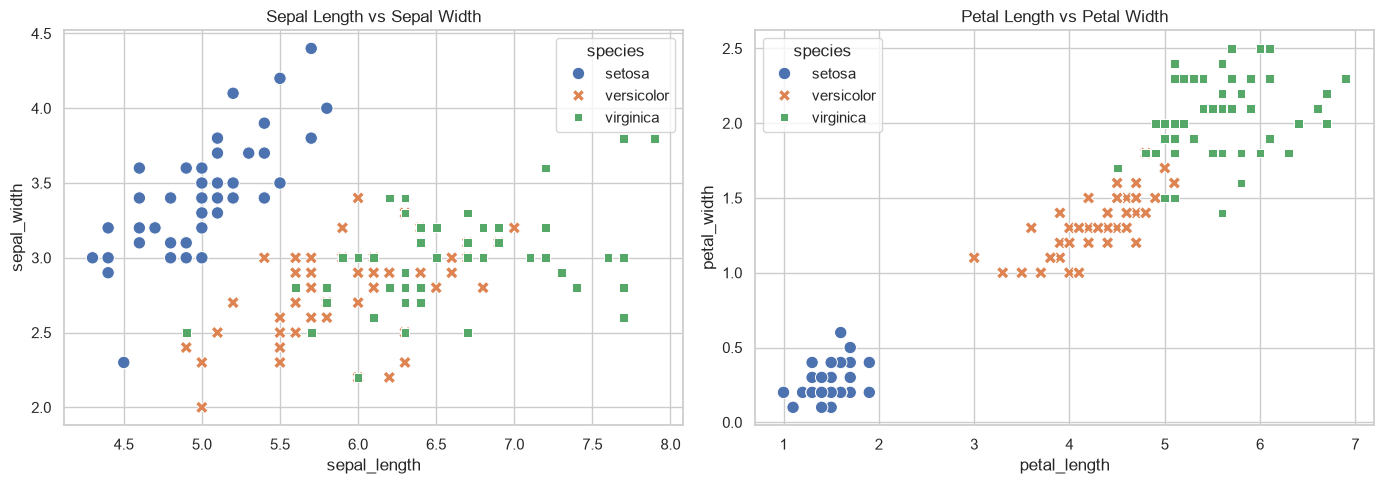


ANALYSIS - SCATTER PLOTS
- In the sepal plot, setosa forms a separate cluster, while versicolor and virginica overlap heavily.
- In the petal plot, all three species form distinct groups: setosa has the smallest petals,
  versicolor medium, and virginica the largest.
- Petal length and petal width show a strong positive linear relationship.
- Petal measurements separate the species better than sepal measurements.



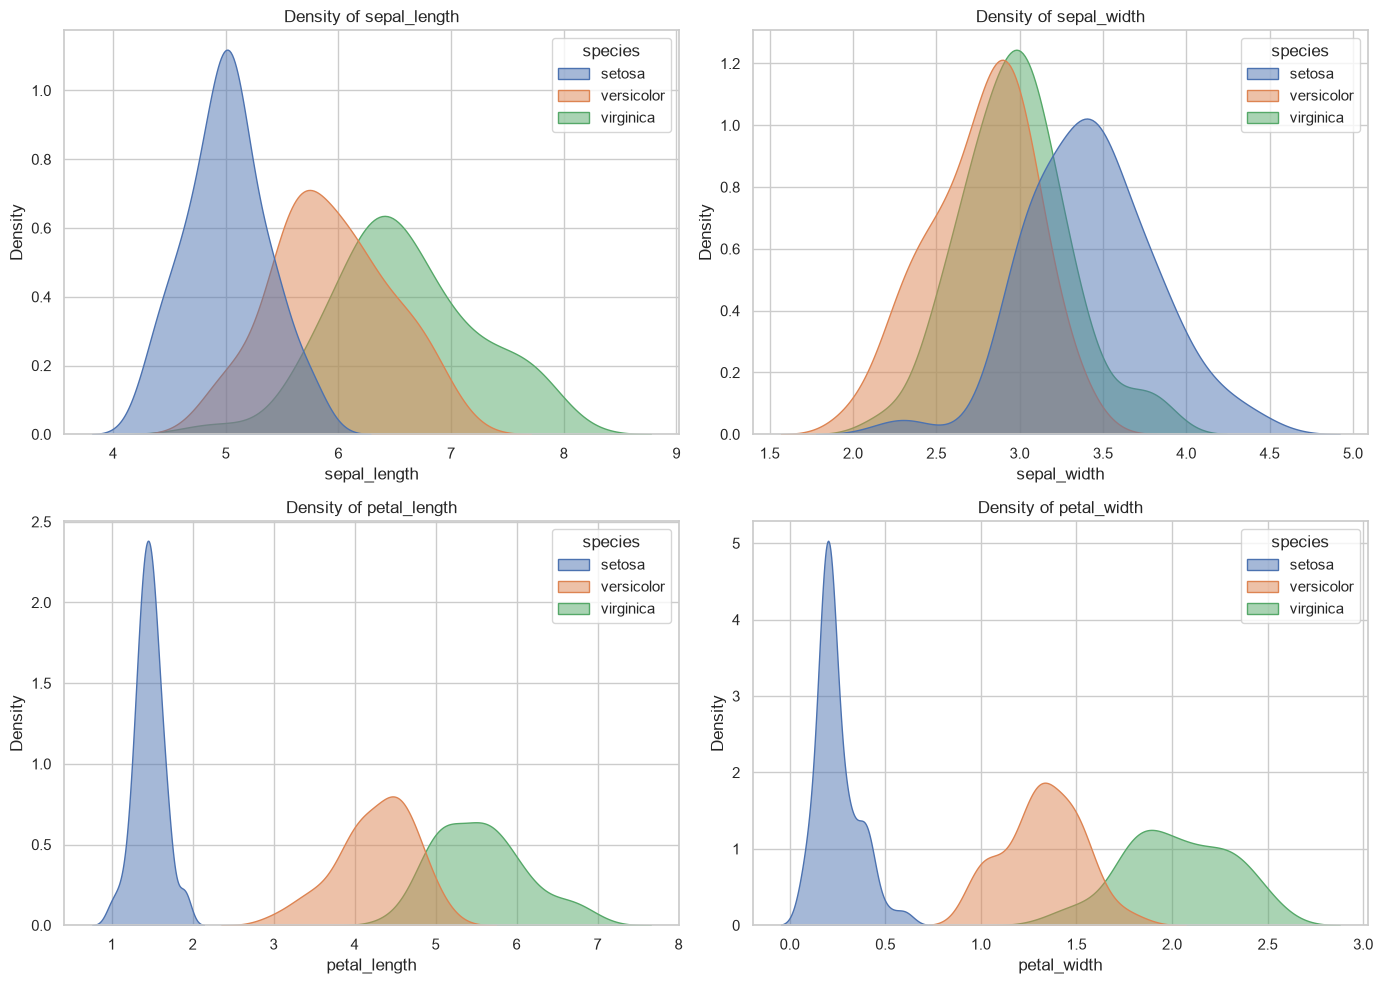


ANALYSIS - DENSITY PLOTS
- Petal length and petal width: setosa has a tall, narrow peak far from the other species, and
  versicolor and virginica overlap only slightly. These features separate the classes best.
- Sepal length: versicolor and virginica overlap substantially, while setosa is shifted lower.
- Sepal width: all species overlap heavily, so it has the least discriminating power.



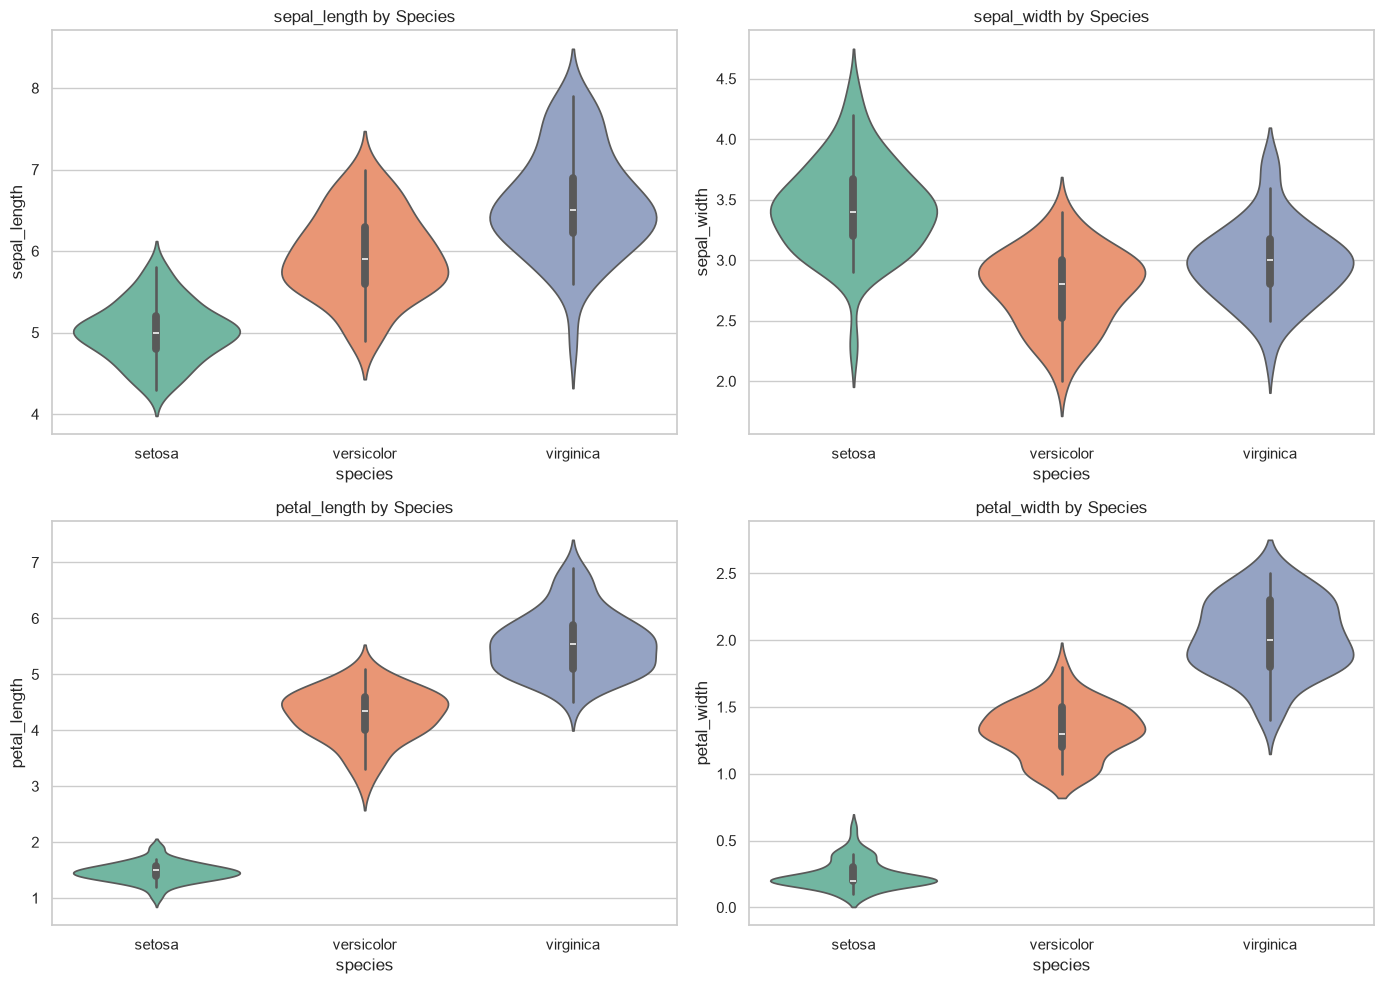


ANALYSIS - VIOLIN PLOTS
- Petal length and width: the violins are clearly separated (setosa < versicolor < virginica),
  and setosa is very narrow, meaning its values are tightly clustered.
- Sepal length: medians increase from setosa to virginica, but the violins overlap.
- Sepal width: setosa has the highest median, versicolor the lowest, with overlapping spread
  and a few outliers.
- Petal features discriminate the species far better than sepal features.



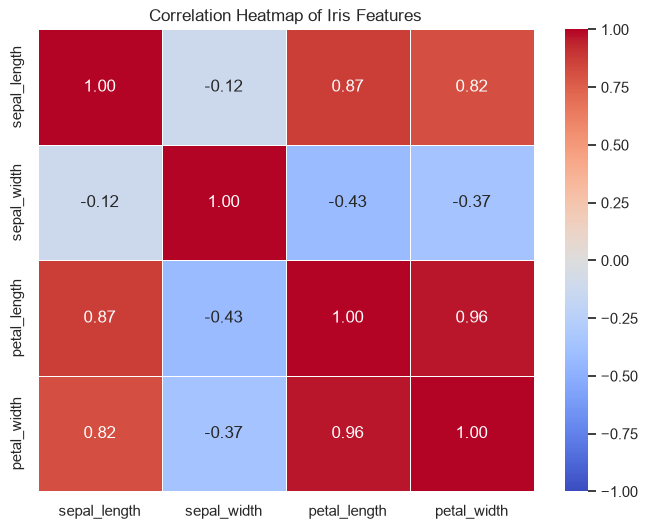


ANALYSIS - HEATMAP (CORRELATION)
- Petal length and petal width (r = 0.96): the strongest positive correlation.
- Sepal length and petal length (r = 0.87), and sepal length and petal width (r = 0.82):
  strong positive correlations.
- Sepal length and sepal width (r = -0.12): very weak, almost no linear relationship.
- Sepal width and petal length (r = -0.43), and sepal width and petal width (r = -0.37):
  moderate negative correlations.
- Petal length, petal width and sepal length are highly correlated with each other (multicollinearity).
- Correlation shows linear association only and does not imply causation.



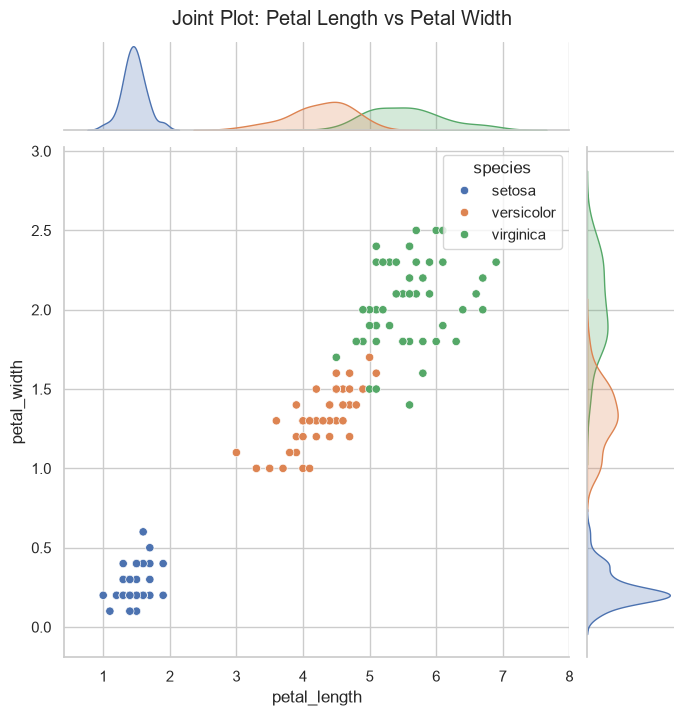

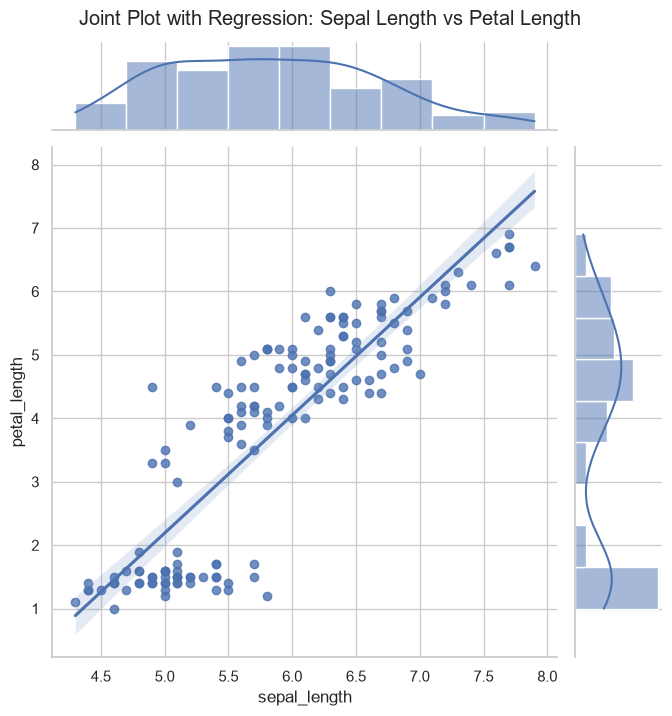


ANALYSIS - JOINT PLOTS
- The marginal distributions show the species are well separated along both petal dimensions,
  with setosa in its own region.
- Petal length and petal width have a strong positive linear relationship (r = 0.96).
- The regression plot shows a clear upward trend between sepal length and petal length (r = 0.87),
  with points close to the fitted line.



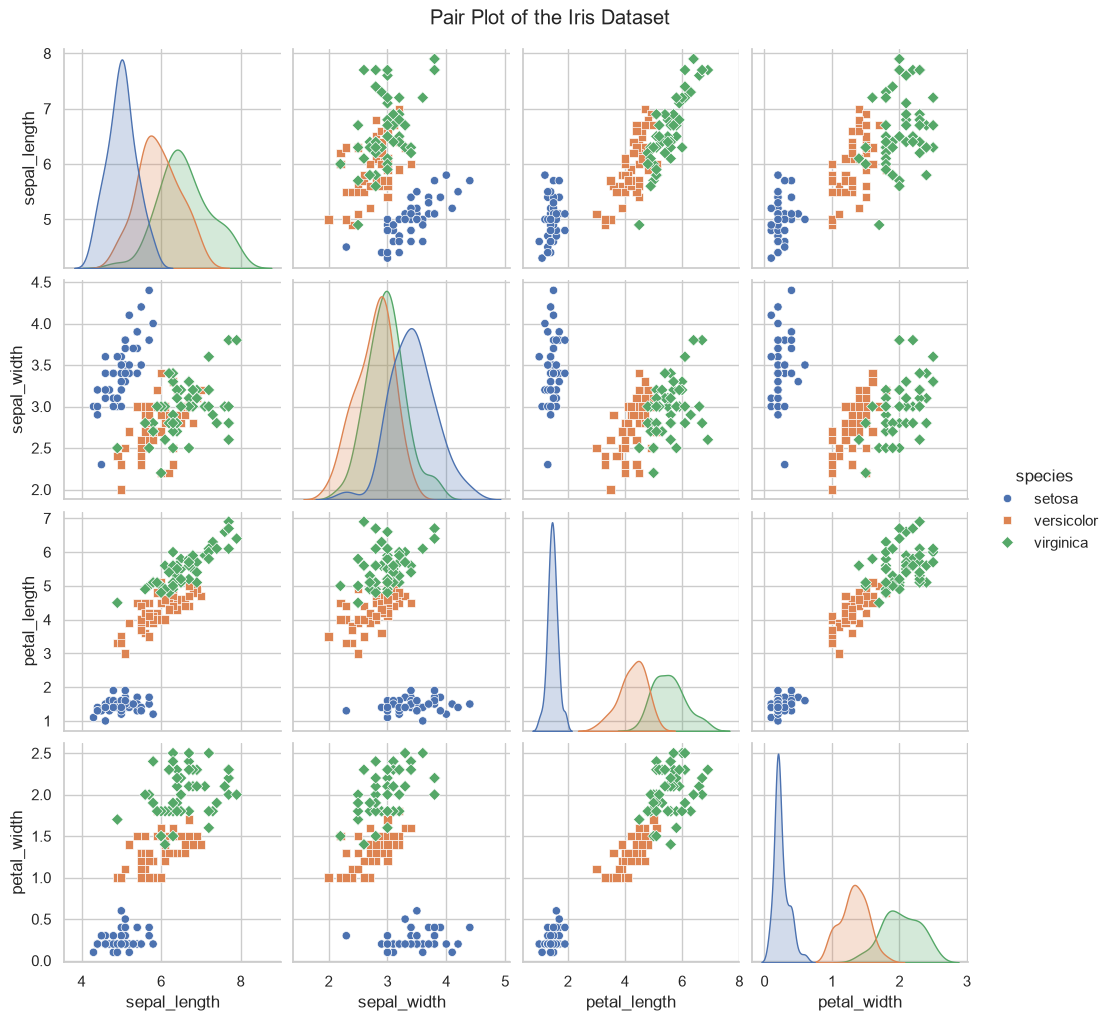


ANALYSIS - PAIR PLOTS
- Setosa is clearly separable from the other two species in almost every plot involving petals.
- Versicolor and virginica overlap in sepal-based plots but separate fairly well in petal-based plots.
- Petal length, petal width and sepal length show strong positive relationships with each other,
  while sepal width shows weaker relationships.

CONCLUSION
Petal length and petal width are the most informative features for distinguishing the species.



In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
iris = sns.load_dataset("iris")
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# 1. SCATTER PLOTS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=iris, x="sepal_length", y="sepal_width", hue="species", style="species", s=80, ax=axes[0])
axes[0].set_title("Sepal Length vs Sepal Width")
sns.scatterplot(data=iris, x="petal_length", y="petal_width", hue="species", style="species", s=80, ax=axes[1])
axes[1].set_title("Petal Length vs Petal Width")
plt.tight_layout()
plt.show()

print("""
ANALYSIS - SCATTER PLOTS
- In the sepal plot, setosa forms a separate cluster, while versicolor and virginica overlap heavily.
- In the petal plot, all three species form distinct groups: setosa has the smallest petals,
  versicolor medium, and virginica the largest.
- Petal length and petal width show a strong positive linear relationship.
- Petal measurements separate the species better than sepal measurements.
""")

# 2. DENSITY PLOTS
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flatten(), features):
    sns.kdeplot(data=iris, x=feature, hue="species", fill=True, common_norm=False, alpha=0.5, ax=ax)
    ax.set_title(f"Density of {feature}")
plt.tight_layout()
plt.show()

print("""
ANALYSIS - DENSITY PLOTS
- Petal length and petal width: setosa has a tall, narrow peak far from the other species, and
  versicolor and virginica overlap only slightly. These features separate the classes best.
- Sepal length: versicolor and virginica overlap substantially, while setosa is shifted lower.
- Sepal width: all species overlap heavily, so it has the least discriminating power.
""")

# 3. VIOLIN PLOTS
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flatten(), features):
    sns.violinplot(data=iris, x="species", y=feature, hue="species", inner="box", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{feature} by Species")
plt.tight_layout()
plt.show()

print("""
ANALYSIS - VIOLIN PLOTS
- Petal length and width: the violins are clearly separated (setosa < versicolor < virginica),
  and setosa is very narrow, meaning its values are tightly clustered.
- Sepal length: medians increase from setosa to virginica, but the violins overlap.
- Sepal width: setosa has the highest median, versicolor the lowest, with overlapping spread
  and a few outliers.
- Petal features discriminate the species far better than sepal features.
""")

# 4. HEATMAP (CORRELATION)
plt.figure(figsize=(8, 6))
corr = iris.drop(columns="species").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, fmt=".2f")
plt.title("Correlation Heatmap of Iris Features")
plt.show()

print("""
ANALYSIS - HEATMAP (CORRELATION)
- Petal length and petal width (r = 0.96): the strongest positive correlation.
- Sepal length and petal length (r = 0.87), and sepal length and petal width (r = 0.82):
  strong positive correlations.
- Sepal length and sepal width (r = -0.12): very weak, almost no linear relationship.
- Sepal width and petal length (r = -0.43), and sepal width and petal width (r = -0.37):
  moderate negative correlations.
- Petal length, petal width and sepal length are highly correlated with each other (multicollinearity).
- Correlation shows linear association only and does not imply causation.
""")

# 5. JOINT PLOTS
g1 = sns.jointplot(data=iris, x="petal_length", y="petal_width", hue="species", kind="scatter", height=7)
g1.fig.suptitle("Joint Plot: Petal Length vs Petal Width", y=1.02)
plt.show()

g2 = sns.jointplot(data=iris, x="sepal_length", y="petal_length", kind="reg", height=7)
g2.fig.suptitle("Joint Plot with Regression: Sepal Length vs Petal Length", y=1.02)
plt.show()

print("""
ANALYSIS - JOINT PLOTS
- The marginal distributions show the species are well separated along both petal dimensions,
  with setosa in its own region.
- Petal length and petal width have a strong positive linear relationship (r = 0.96).
- The regression plot shows a clear upward trend between sepal length and petal length (r = 0.87),
  with points close to the fitted line.
""")

# 6. PAIR PLOTS
g3 = sns.pairplot(iris, hue="species", diag_kind="kde", markers=["o", "s", "D"], height=2.5)
g3.fig.suptitle("Pair Plot of the Iris Dataset", y=1.02)
plt.show()

print("""
ANALYSIS - PAIR PLOTS
- Setosa is clearly separable from the other two species in almost every plot involving petals.
- Versicolor and virginica overlap in sepal-based plots but separate fairly well in petal-based plots.
- Petal length, petal width and sepal length show strong positive relationships with each other,
  while sepal width shows weaker relationships.

CONCLUSION
Petal length and petal width are the most informative features for distinguishing the species.
""")